# Projet 1 : maintenance prédictive d'une valve hydraulique

**Objectif :** prédire si la condition de la valve est optimale ou non à chaque cycle de production, et comprendre ce qui la rend non optimale.

**Consigne :** Construisez un modèle ML pour prédire si la condition valve est optimale (=100%) ou non, pour chaque cycle. Vous utiliserez les 2000 premiers cycles pour construire le modèle et le reste comme échantillon de test final.

## 1. Compréhension du problème et des données

**Problématique** : à partir des mesures de pression (PS2) et de débit (FS1) enregistrées
pendant un cycle de production de 60 s, prédire si la condition de la valve est optimale
(= 100 %) ou non. C'est un problème de **classification binaire**.

**Structure des fichiers** (d'après la documentation du dataset, vérifiée ci-dessous) :
- Chaque **ligne** = un **cycle** de 60 secondes (2205 cycles au total).
- Chaque **colonne** = une mesure à **un instant du cycle** : une ligne est donc une
  courbe temporelle.

| Fichier | Grandeur | Unité | Fréquence | Colonnes attendues |
|---|---|---|---|---|
| PS2 | Pression hydraulique | bar | 100 Hz | 100 × 60 = 6000 |
| FS1 | Débit volumique | l/min | 10 Hz | 10 × 60 = 600 |

**profile.txt** (sans en-tête, noms issus de la documentation) :

| Colonne | Nom | Valeurs possibles |
|---|---|---|
| 0 | cooler condition (%) | 3, 20, 100 |
| **1** | **valve condition (%)** ← cible | 73, 80, 90, 100 |
| 2 | internal pump leakage | 0, 1, 2 |
| 3 | hydraulic accumulator (bar) | 90, 100, 115, 130 |
| 4 | stable flag | 0, 1 |

**Cible** : `y = 1` si valve = 100 (optimal), `y = 0` sinon (73, 80 ou 90).

**Split imposé** : les 2000 premiers cycles servent à l'entraînement, les 205 suivants au test final.

**Variables exclues** : cooler, pump leakage et accumulator décrivent l'état d'autres
composants. Ce ne sont pas des mesures de capteurs : on ne les connaîtrait pas en
production, donc les utiliser comme features serait une fuite de données (data leakage).


### 1.1 Chargement et aperçu des données

In [1]:
## Type de données : données en txt 
# Importation des bibliothèques necessaires 
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
## path to the data 
path1 = "data/FS1.txt"
path2 = "data/PS2.txt"
path3 = "data/profile.txt"

In [3]:
## load the data (txt file )
df_FS= pd.read_csv(path1, sep='\t', header=None) #separator is tabulation
df_PS= pd.read_csv(path2, sep='\t', header=None)
df_profile= pd.read_csv(path3, sep='\t', header=None)

In [4]:
## On va bien renommer les colonnes du dataframe df_profile pour faciliter l'analyse et la compréhension des données. Les nouvelles colonnes seront : "cooler", "valve", "pump_leak", "accumulator", et "stable_flag".
df_profile.columns = ["cooler", "valve", "pump_leak", "accumulator", "stable_flag"]
print(df_PS.shape, df_FS.shape, df_profile.shape)   # (2205, 6000) (2205, 600) (2205, 5)
for c in df_profile.columns:
    print(c, sorted(df_profile[c].unique()))


(2205, 6000) (2205, 600) (2205, 5)
cooler [np.int64(3), np.int64(20), np.int64(100)]
valve [np.int64(73), np.int64(80), np.int64(90), np.int64(100)]
pump_leak [np.int64(0), np.int64(1), np.int64(2)]
accumulator [np.int64(90), np.int64(100), np.int64(115), np.int64(130)]
stable_flag [np.int64(0), np.int64(1)]


In [5]:
#exploration des données 
df_FS.info()
df_PS.info()
df_profile.info()

<class 'pandas.DataFrame'>
RangeIndex: 2205 entries, 0 to 2204
Columns: 600 entries, 0 to 599
dtypes: float64(600)
memory usage: 10.1 MB
<class 'pandas.DataFrame'>
RangeIndex: 2205 entries, 0 to 2204
Columns: 6000 entries, 0 to 5999
dtypes: float64(6000)
memory usage: 100.9 MB
<class 'pandas.DataFrame'>
RangeIndex: 2205 entries, 0 to 2204
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   cooler       2205 non-null   int64
 1   valve        2205 non-null   int64
 2   pump_leak    2205 non-null   int64
 3   accumulator  2205 non-null   int64
 4   stable_flag  2205 non-null   int64
dtypes: int64(5)
memory usage: 86.3 KB


In [6]:
df_FS.head()

,0,1,2,3,4,5,6,7,8,9,...,590,591,592,593,594,595,596,597,598,599
0,8.990,0.770,0.641,0.006,0.000,0.000,0.001,0.003,0.001,0.001,...,7.743,7.992,7.919,7.773,7.955,7.823,7.963,7.876,7.738,8.036
1,8.919,0.815,0.709,0.009,0.004,0.000,0.001,0.000,0.000,0.001,...,7.831,8.003,7.923,7.745,7.867,7.747,7.969,7.969,7.963,7.890
2,9.179,0.683,0.528,0.008,0.003,0.001,0.003,0.003,0.004,0.006,...,7.862,7.815,7.894,7.743,7.936,7.770,7.982,7.873,7.898,7.952
3,9.034,0.728,0.595,0.009,0.001,0.004,0.003,0.003,0.003,0.001,...,7.631,7.949,7.773,8.054,7.827,8.011,7.919,7.938,7.877,7.773
4,8.729,0.705,0.446,0.014,0.007,0.003,0.001,0.003,0.001,0.000,...,7.771,7.936,7.919,7.946,7.804,7.983,7.838,7.882,7.894,7.825


In [7]:
df_PS.head()

,0,1,2,3,4,5,6,7,8,9,...,5990,5991,5992,5993,5994,5995,5996,5997,5998,5999
0,125.50,125.39,125.40,125.03,124.05,123.18,104.01,56.500,23.992,18.406,...,125.02,125.00,125.10,125.09,124.98,124.91,124.98,125.11,125.14,125.10
1,125.06,125.08,125.09,124.69,123.84,123.14,103.63,63.687,28.359,21.711,...,124.80,124.88,125.13,125.22,125.09,124.98,125.06,125.13,125.09,125.04
2,125.13,125.27,125.23,124.74,123.94,123.23,106.35,60.516,26.258,19.258,...,124.61,124.69,124.74,124.71,124.59,124.64,124.74,124.73,124.77,124.88
3,124.93,124.96,124.92,124.41,123.60,122.88,103.99,58.859,27.781,21.469,...,124.82,124.79,124.69,124.69,124.77,124.83,124.69,124.53,124.51,124.59
4,124.72,124.74,124.66,124.31,123.57,122.74,105.94,62.648,30.875,23.883,...,124.80,124.67,124.49,124.56,124.69,124.62,124.45,124.41,124.47,124.51


In [8]:
df_profile.head()

,cooler,valve,pump_leak,accumulator,stable_flag
0,3,100,0,130,1
1,3,100,0,130,1
2,3,100,0,130,1
3,3,100,0,130,1
4,3,100,0,130,1


### 1.2 Split train / test

Les 2000 premiers cycles forment le train, les 205 derniers le test. Toute analyse qui utilise la cible se fait sur le train ; le test ne sert qu'à l'évaluation finale (partie 5).

In [9]:
N_TRAIN = 2000   # consigne : 2000 premiers cycles = train, le reste = test final

y = (df_profile["valve"] == 100).astype(int)   # 1 = optimal, 0 = non optimal

# Vues "train" : toute analyse qui utilise la cible passe par elles
PS_tr, FS_tr = df_PS.iloc[:N_TRAIN], df_FS.iloc[:N_TRAIN]
prof_tr, y_tr = df_profile.iloc[:N_TRAIN], y.iloc[:N_TRAIN]

## 2. Prétraitement des données


### 2.1 Qualité des données

Types, valeurs manquantes et doublons : un cycle en double pourrait se retrouver à la fois dans le train et dans le test.

In [10]:
for name, df in [("PS2", df_PS), ("FS1", df_FS), ("profile", df_profile)]:
    print(f"{name:8s} | shape = {df.shape} | types = {df.dtypes.value_counts().to_dict()} "
          f"| NaN = {df.isna().sum().sum()} | lignes dupliquées = {df.duplicated().sum()}")

PS2      | shape = (2205, 6000) | types = {dtype('float64'): 6000} | NaN = 0 | lignes dupliquées = 0
FS1      | shape = (2205, 600) | types = {dtype('float64'): 600} | NaN = 0 | lignes dupliquées = 0
profile  | shape = (2205, 5) | types = {dtype('int64'): 5} | NaN = 0 | lignes dupliquées = 2025


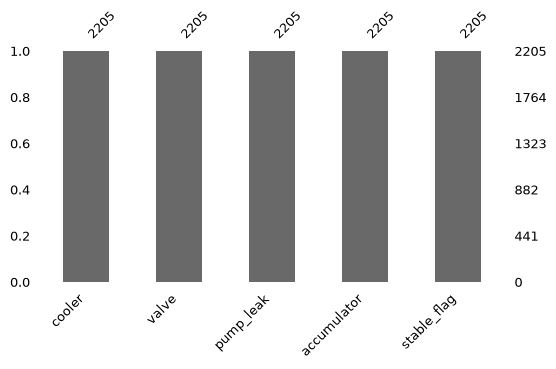

In [11]:
# Visualisation des valeurs manquantes 
import missingno as msno
msno.bar(df_profile, figsize=(6, 3), fontsize=9)
plt.show()

**Conclusion :** données 100 % numériques, aucun NaN, aucun cycle dupliqué dans PS2 ni FS1. Les doublons de profile sont normaux (5 colonnes à peu de valeurs : les mêmes combinaisons reviennent). **Aucune imputation nécessaire.**

### 2.2 Valeurs aberrantes

- **Impossibles** (erreur de capteur) : pression ou débit négatif, à corriger.
- **Extrêmes** (règle IQR) : souvent des cycles dégradés, donc de l'information à garder.

Un 0 n'est pas une erreur : le débit est nul quand le circuit est à l'arrêt.

In [12]:
# 1) Valeurs physiquement impossibles
print("Valeurs négatives  PS2 :", (df_PS < 0).sum().sum(), "| FS1 :", (df_FS < 0).sum().sum())
print(f"Plage PS2 : [{df_PS.values.min():.2f} ; {df_PS.values.max():.2f}] bar")
print(f"Plage FS1 : [{df_FS.values.min():.2f} ; {df_FS.values.max():.2f}] l/min")

Valeurs négatives  PS2 : 0 | FS1 : 0
Plage PS2 : [0.00 ; 167.77] bar
Plage FS1 : [0.00 ; 20.48] l/min


Nombre de cycles extrêmes :
 PS2_mean    240
FS1_mean    240
dtype: int64


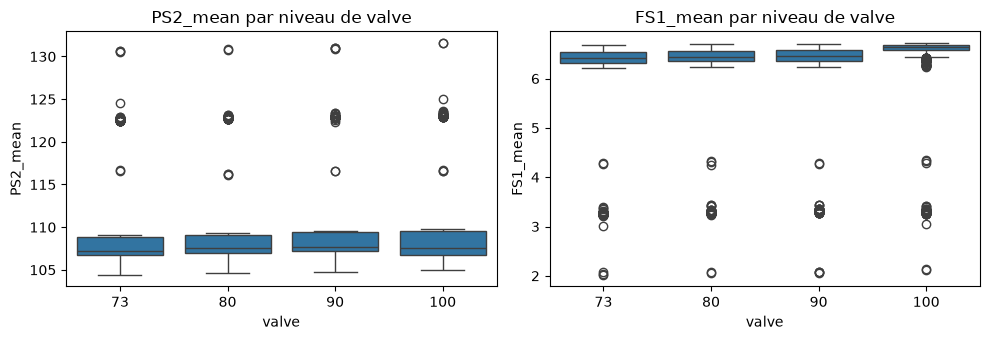

In [13]:
# 2) Cycles statistiquement extrêmes (règle IQR appliquée à la moyenne de chaque cycle)
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)

cycle_means = pd.DataFrame({"PS2_mean": PS_tr.mean(axis=1), "FS1_mean": FS_tr.mean(axis=1)})
outliers = cycle_means.apply(iqr_outliers)
print("Nombre de cycles extrêmes :\n", outliers.sum())

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, col in zip(axes, cycle_means.columns):
    sns.boxplot(x=prof_tr["valve"], y=cycle_means[col], ax=ax)
    ax.set_title(f"{col} par niveau de valve")
plt.tight_layout()
plt.show()

In [14]:
# 3) Le stable_flag : cycles où le système n'était peut-être pas encore stabilisé
print(pd.crosstab(prof_tr["stable_flag"], prof_tr["valve"], margins=True))

valve         73   80   90   100   All
stable_flag                           
0            320  318  310   310  1258
1              0    0    0   742   742
All          320  318  310  1052  2000


**Conclusion :** aucune valeur négative, plages cohérentes. Les cycles extrêmes sont des mesures réelles liées à l'état des composants : **on les garde**, et on standardisera avant les modèles sensibles à l'échelle.

⚠️ `stable_flag = 1` n'apparaît que pour valve = 100 : l'utiliser reviendrait à deviner la cible (**fuite de données**). Il est exclu, comme le reste de profile.

### 2.3 Encodage

PS2 et FS1 sont continues et profile est déjà codé en niveaux ordonnés : **aucun encodage nécessaire**. Seule la cible est transformée.

### 2.4 Cible et équilibre des classes

`y = 1` si valve = 100 (optimal), `y = 0` sinon (73, 80 ou 90).

                 proportion
0 = non optimal       0.474
1 = optimal           0.526


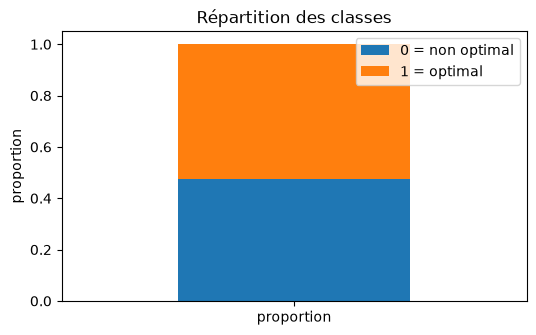

In [15]:
balance = y_tr.value_counts(normalize=True).sort_index().to_frame()
balance.index = ["0 = non optimal", "1 = optimal"]
print(balance)

balance.T.plot(kind="bar", stacked=True, figsize=(6, 3.5), rot=0)
plt.ylabel("proportion")
plt.title("Répartition des classes")
plt.show()

**Conclusion :** classes équilibrées (47 % / 53 %). On suivra la **balanced accuracy**, qui donne le même poids à la classe 0 (valve dégradée, celle qui déclenche une maintenance).

### 2.5 Signaux bruts

Courbe moyenne par niveau de valve : à quel moment du cycle les valves se distinguent-elles ?

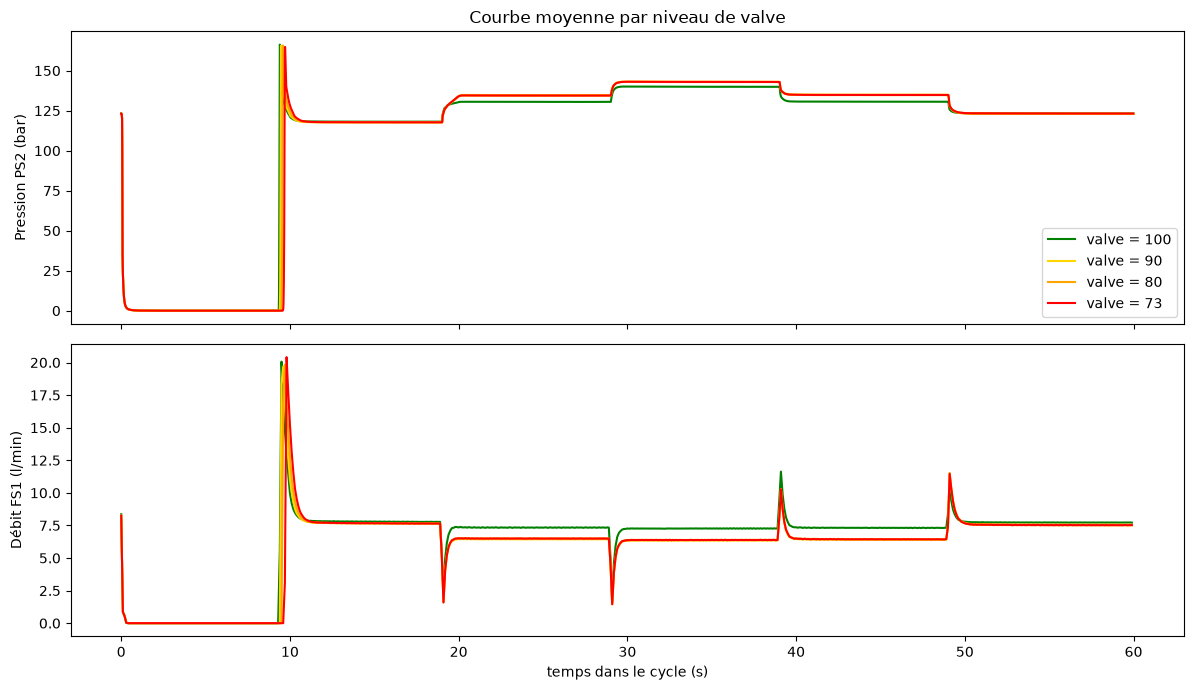

In [16]:
t_ps = np.arange(PS_tr.shape[1]) / 100   # axe du temps en secondes (100 Hz)
t_fs = np.arange(FS_tr.shape[1]) / 10    # 10 Hz

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for v, color in zip([100, 90, 80, 73], ["green", "gold", "orange", "red"]):
    mask = prof_tr["valve"] == v
    axes[0].plot(t_ps, PS_tr[mask].mean(), label=f"valve = {v}", color=color)
    axes[1].plot(t_fs, FS_tr[mask].mean(), label=f"valve = {v}", color=color)
axes[0].set_ylabel("Pression PS2 (bar)")
axes[1].set_ylabel("Débit FS1 (l/min)")
axes[1].set_xlabel("temps dans le cycle (s)")
axes[0].set_title("Courbe moyenne par niveau de valve")
axes[0].legend()
plt.tight_layout()
plt.show()

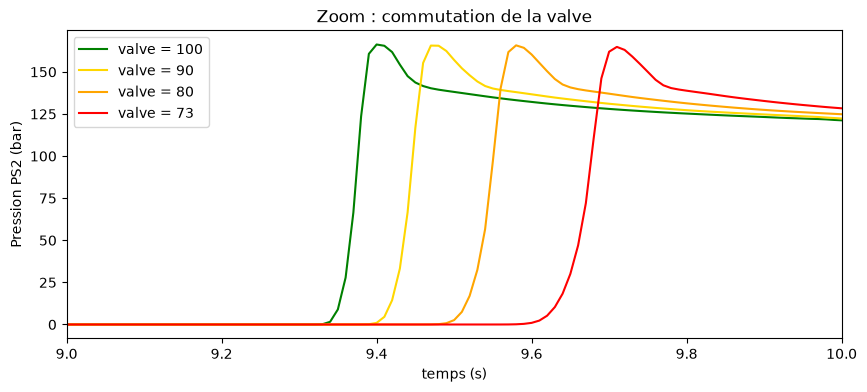

In [17]:
# Zoom sur la zone où les courbes divergent
fig, ax = plt.subplots(figsize=(10, 4))
for v, color in zip([100, 90, 80, 73], ["green", "gold", "orange", "red"]):
    ax.plot(t_ps, PS_tr[prof_tr["valve"] == v].mean(), label=f"valve = {v}", color=color)
ax.set_xlim(9, 10)
ax.set_xlabel("temps (s)")
ax.set_ylabel("Pression PS2 (bar)")
ax.set_title("Zoom : commutation de la valve")
ax.legend()
plt.show()

**Conclusion :** les courbes ne diffèrent vraiment qu'entre **9 et 10 s**, à la commutation de la valve : plus la valve est dégradée, plus la montée en pression est **retardée**. La moyenne globale d'un cycle ne suffira pas : il faut des features qui capturent le temps.

### 2.6 Extraction de features

Les 6600 colonnes brutes sont très redondantes : on résume chaque cycle.
- **Statistiques globales** par capteur : moyenne, écart-type, max, médiane, skew, kurtosis (le min vaut toujours 0).
- **Moyenne par seconde** : 60 valeurs par capteur, pour garder l'information temporelle.

Ces features sont **sans état** (calculées cycle par cycle, sans la cible) : les calculer avant le split ne crée aucune fuite.

In [18]:
def global_stats(df, prefix):
    # Statistiques résumant la forme globale de chaque courbe (une ligne = un cycle)
    # Le min n'est pas calculé : il vaut 0 pour tous les cycles, sur les deux capteurs
    return pd.DataFrame({
        f"{prefix}_mean":   df.mean(axis=1),
        f"{prefix}_std":    df.std(axis=1),
        f"{prefix}_max":    df.max(axis=1),
        f"{prefix}_median": df.median(axis=1),
        f"{prefix}_skew":   df.skew(axis=1),
        f"{prefix}_kurt":   df.kurt(axis=1),
    })

def per_second_means(df, freq, prefix):
    # (n_cycles, 60 * freq) -> (n_cycles, 60, freq) -> moyenne sur chaque seconde
    values = df.values.reshape(len(df), -1, freq).mean(axis=2)
    return pd.DataFrame(values, columns=[f"{prefix}_s{i:02d}" for i in range(values.shape[1])])




In [19]:
stats_feats = pd.concat([global_stats(df_PS, "PS2"), global_stats(df_FS, "FS1")], axis=1)
time_feats = pd.concat([per_second_means(df_PS, 100, "PS2"), per_second_means(df_FS, 10, "FS1")], axis=1)

## X = features finales pour l'apprentissage automatique
X = pd.concat([stats_feats, time_feats], axis=1)
print("Dimensions de X :", X.shape)   # attendu : (2205, 132) = 2 × 6 stats + 2 × 60 secondes
X.head()

Dimensions de X : (2205, 132)


,PS2_mean,PS2_std,PS2_max,PS2_median,PS2_skew,PS2_kurt,FS1_mean,FS1_std,FS1_max,FS1_median,...,FS1_s50,FS1_s51,FS1_s52,FS1_s53,FS1_s54,FS1_s55,FS1_s56,FS1_s57,FS1_s58,FS1_s59
0,109.466914,47.114508,156.99,129.365,-1.838312,1.511113,6.709815,3.015428,18.710,7.836,...,7.8893,7.8619,7.8464,7.8978,7.8668,7.8796,7.8441,7.8724,7.8635,7.8818
1,109.354890,47.045611,157.56,129.385,-1.838811,1.513347,6.715315,3.006248,18.712,7.853,...,7.9110,7.8836,7.8769,7.8764,7.8895,7.8802,7.8970,7.8870,7.8770,7.8907
2,109.158845,46.992060,156.97,129.325,-1.838005,1.510739,6.718522,3.014248,18.698,7.847,...,7.9037,7.9011,7.8782,7.8894,7.8711,7.8497,7.8846,7.8882,7.8832,7.8725
3,109.064807,46.972221,156.44,128.865,-1.837580,1.509871,6.720565,3.020176,18.896,7.843,...,7.9188,7.8778,7.8813,7.8909,7.8724,7.8931,7.8569,7.8707,7.8862,7.8752
4,108.931434,46.874946,158.13,129.000,-1.837956,1.511983,6.690308,3.011550,18.876,7.831,...,7.8809,7.8217,7.8942,7.8621,7.8300,7.8693,7.8206,7.8866,7.8436,7.8798


### 2.7 Instants de montée

La valve agit sur le **moment** de la montée (2.5) : on le mesure directement, comme le premier instant où le signal dépasse un seuil autour de la commutation.
- **PS2** : seuil 50 bar, fenêtre 8,8 à 10,5 s (pression proche de 0 avant, plus de 150 bar après).
- **FS1** : seuil 1 l/min, fenêtre 8,8 à 11 s.

Feature sans état, comme les précédentes.

In [20]:
DEBUT, FIN = 880, 1050   # fenêtre de recherche : de 8,8 s à 10,5 s (indices à 100 Hz)
SEUIL = 50               # bar

fenetre = df_PS.values[:, DEBUT:FIN]    # (2205, 170) : la portion utile de chaque courbe
au_dessus = fenetre > SEUIL             # True là où la pression dépasse le seuil

# Garde-fous : la fenêtre doit commencer sous le seuil, et la montée doit exister
assert (fenetre[:, 0] < SEUIL).all(), "Certains cycles sont déjà au-dessus du seuil à 8,8 s"
assert au_dessus.any(axis=1).all(), "Certains cycles ne dépassent jamais le seuil"

idx = au_dessus.argmax(axis=1)          # position du premier True de chaque ligne
t_montee = pd.Series((DEBUT + idx) / 100, name="PS2_t_montee")   # en secondes

pd.crosstab(prof_tr["valve"], t_montee[:N_TRAIN])

PS2_t_montee,9.37,9.38,9.39,9.44,9.45,9.46,9.54,9.55,9.57,9.66,9.67,9.68,9.69,9.70
valve,,,,,,,,,,,,,,
73,0,0,0,0,0,0,0,0,0,119,184,13,1,3
80,0,0,0,0,0,0,225,91,2,0,0,0,0,0
90,0,0,0,251,55,4,0,0,0,0,0,0,0,0
100,875,176,1,0,0,0,0,0,0,0,0,0,0,0


**Lecture :** sur PS2, chaque niveau de valve a sa propre plage d'instants, **sans aucun chevauchement** : de 9,37 s pour une valve optimale à 9,70 s pour une valve à 73 %.

In [21]:
DEBUT_FS, FIN_FS = 88, 110   # de 8,8 s à 11,0 s (indices à 10 Hz)
SEUIL_FS = 1                 # l/min

fenetre_fs = df_FS.values[:, DEBUT_FS:FIN_FS]
au_dessus_fs = fenetre_fs > SEUIL_FS

assert (fenetre_fs[:, 0] < SEUIL_FS).all()
assert au_dessus_fs.any(axis=1).all()

t_montee_fs = pd.Series((DEBUT_FS + au_dessus_fs.argmax(axis=1)) / 10, name="FS1_t_montee")

# Combien de cycles de chaque niveau tombent à chaque instant ?
pd.crosstab(prof_tr["valve"], t_montee_fs[:N_TRAIN])

FS1_t_montee,9.4,9.5,9.6,9.7,9.8
valve,,,,,
73,0,0,0,202,118
80,0,0,317,1,0
90,0,310,0,0,0
100,842,210,0,0,0


**Lecture :** FS1 est échantillonné 10 fois moins vite : 210 valves optimales tombent à 9,5 s, comme les valves à 90 %. La feature est gardée, mais PS2 est plus précis.

On ajoute les deux instants de montée à `X`.

In [22]:
X["PS2_t_montee"] = t_montee
X["FS1_t_montee"] = t_montee_fs

X_train, X_test = X.iloc[:N_TRAIN], X.iloc[N_TRAIN:]
print("Dimensions de X :", X.shape)   # attendu : (2205, 134)

Dimensions de X : (2205, 134)


### 2.8 Distributions des features

Une bonne feature a des distributions **peu superposées** entre `y = 0` et `y = 1`.

In [23]:
# Toutes les analyses qui utilisent la cible se font sur le train uniquement
stats_tr = stats_feats.iloc[:N_TRAIN]

stats_tr.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
PS2_mean,2000.0,109.39,5.23,104.41,106.83,107.56,109.38,131.59
PS2_std,2000.0,47.78,3.43,45.21,46.16,46.64,47.16,59.55
PS2_max,2000.0,166.45,1.00,155.04,166.10,166.57,167.02,167.74
PS2_median,2000.0,128.55,3.62,124.44,127.02,127.81,129.88,165.40
PS2_skew,2000.0,-1.77,0.15,-1.84,-1.84,-1.83,-1.79,-1.32
PS2_kurt,2000.0,1.35,0.31,0.46,1.34,1.48,1.51,1.52
FS1_mean,2000.0,6.16,1.08,2.02,6.38,6.58,6.65,6.72
FS1_std,2000.0,3.05,0.20,2.67,2.96,2.98,3.02,3.74
FS1_max,2000.0,20.14,0.45,18.70,19.91,20.40,20.48,20.48
FS1_median,2000.0,6.92,2.08,1.10,7.47,7.70,7.80,7.85


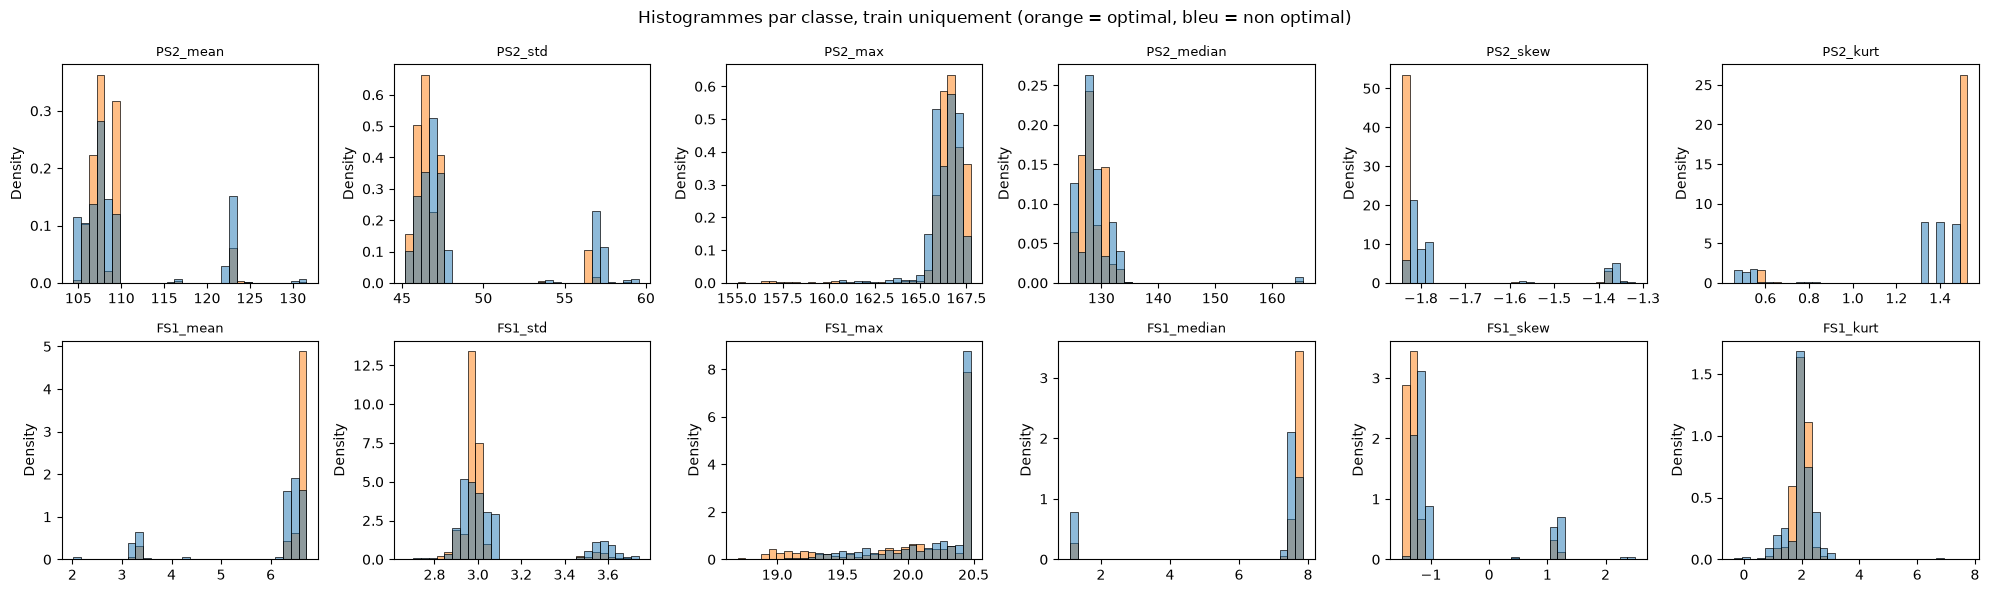

In [24]:
fig, axes = plt.subplots(2, 6, figsize=(20, 6))
for ax, col in zip(axes.ravel(), stats_tr.columns):
    sns.histplot(x=stats_tr[col], hue=y_tr, ax=ax, bins=30, stat="density", common_norm=False, legend=False)
    ax.set_title(col, fontsize=9)
    ax.set_xlabel("")
fig.suptitle("Histogrammes par classe, train uniquement (orange = optimal, bleu = non optimal)")
plt.tight_layout()
plt.show()

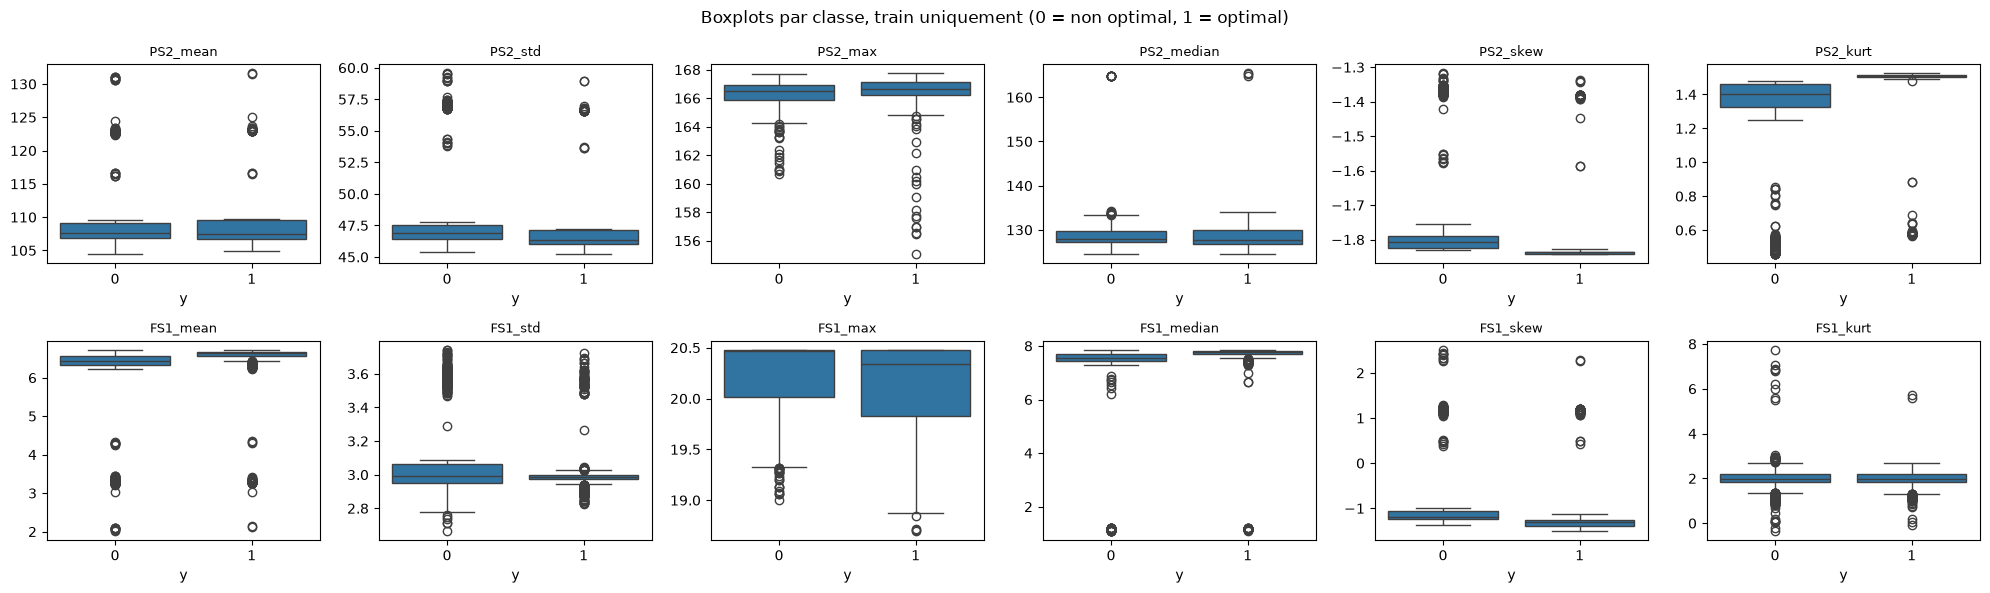

In [25]:
fig, axes = plt.subplots(2, 6, figsize=(20, 6))
for ax, col in zip(axes.ravel(), stats_tr.columns):
    sns.boxplot(x=y_tr, y=stats_tr[col], ax=ax)
    ax.set_title(col, fontsize=9)
    ax.set_xlabel("y")
    ax.set_ylabel("")
fig.suptitle("Boxplots par classe, train uniquement (0 = non optimal, 1 = optimal)")
plt.tight_layout()
plt.show()

**Lecture :** aucune statistique globale ne sépare nettement les classes. `PS2_kurt`, `PS2_skew` et `FS1_mean` les séparent en partie, mais avec du chevauchement : la forme globale du cycle ne suffit pas.

### 2.9 Corrélations entre features

Deux features très corrélées apportent la même information.

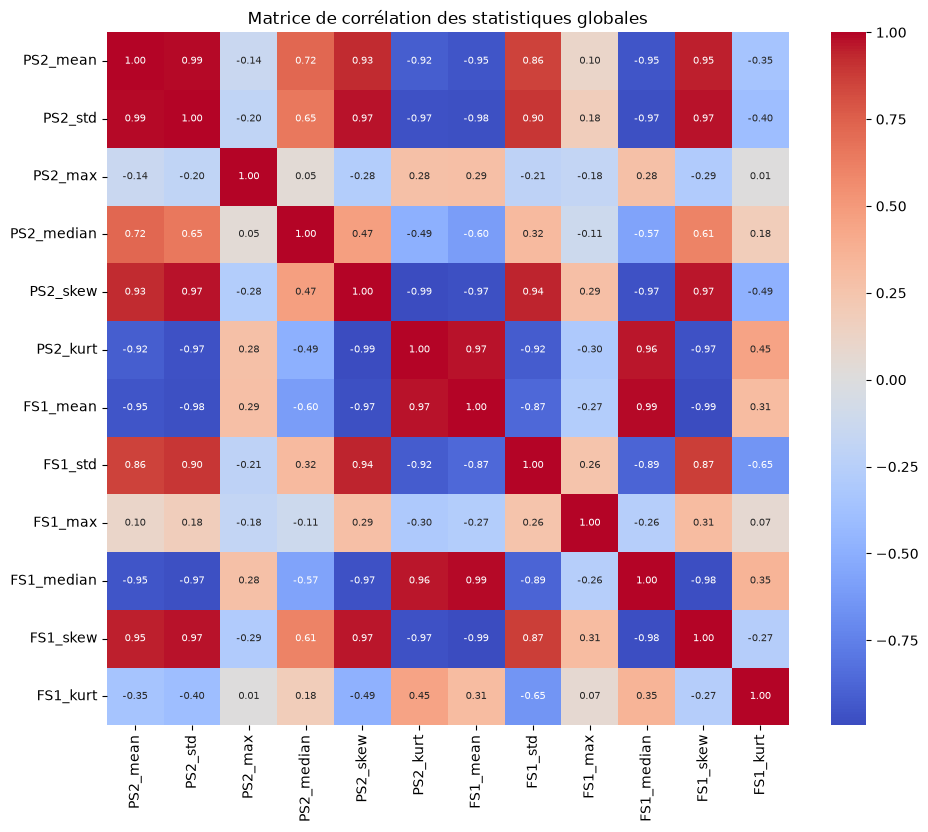

In [26]:
plt.figure(figsize=(11, 9))
sns.heatmap(stats_tr.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 7})
plt.title("Matrice de corrélation des statistiques globales")
plt.show()

**Lecture :** les statistiques globales sont très corrélées entre elles (souvent |r| > 0,9, par exemple 0,99 entre `PS2_mean` et `PS2_std`) : elles portent presque la même information. Raison de plus pour cibler la commutation.

### 2.10 Jeux finaux train / test

On découpe `X` (134 features) selon la consigne.

In [27]:

# Jeux finaux : les features (sans état) découpées selon la consigne
X_train, y_train = X.iloc[:N_TRAIN], y_tr
X_test,  y_test  = X.iloc[N_TRAIN:], y.iloc[N_TRAIN:]   # ne servira qu'à l'évaluation finale

## 3. Protocole de validation

### 3.1 Validation croisée par blocs

Les cycles arrivent par **séries** : des cycles consécutifs mesurés dans les mêmes conditions, aux courbes quasi identiques. Un K-fold aléatoire mettrait ces quasi-doublons à la fois en entraînement et en validation, et gonflerait le score.

On découpe donc le train en **20 blocs de 100 cycles consécutifs** (environ 10 fois la longueur d'une série) et on utilise `GroupKFold` à 5 folds : un bloc n'est jamais coupé entre entraînement et validation.

In [28]:
from sklearn.model_selection import GroupKFold, cross_validate

TAILLE_BLOC = 100
groups = np.arange(N_TRAIN) // TAILLE_BLOC   # numéro de bloc de chaque cycle (0 à 19)
cv = GroupKFold(n_splits=5)

# Contrôle : aucun bloc partagé, et les deux classes présentes dans chaque fold de validation
for k, (idx_fit, idx_val) in enumerate(cv.split(X_train, y_train, groups)):
    blocs_val = sorted(int(b) for b in set(groups[idx_val]))
    blocs_communs = set(groups[idx_fit]) & set(groups[idx_val])
    print(f"fold {k} | blocs de validation = {blocs_val} | "
          f"{len(idx_fit)} cycles d'entraînement, {len(idx_val)} de validation | "
          f"part de y=1 en validation = {y_train.iloc[idx_val].mean():.2f} | "
          f"blocs communs = {len(blocs_communs)}")

fold 0 | blocs de validation = [4, 9, 14, 19] | 1600 cycles d'entraînement, 400 de validation | part de y=1 en validation = 0.44 | blocs communs = 0
fold 1 | blocs de validation = [3, 8, 13, 18] | 1600 cycles d'entraînement, 400 de validation | part de y=1 en validation = 0.48 | blocs communs = 0
fold 2 | blocs de validation = [2, 7, 12, 17] | 1600 cycles d'entraînement, 400 de validation | part de y=1 en validation = 0.44 | blocs communs = 0
fold 3 | blocs de validation = [1, 6, 11, 16] | 1600 cycles d'entraînement, 400 de validation | part de y=1 en validation = 0.60 | blocs communs = 0
fold 4 | blocs de validation = [0, 5, 10, 15] | 1600 cycles d'entraînement, 400 de validation | part de y=1 en validation = 0.66 | blocs communs = 0


**Vérification :** aucun bloc partagé, et les deux classes sont présentes dans chaque fold (part de `y = 1` entre 0,44 et 0,66, sans effet sur les métriques choisies).

### 3.2 Métriques

- **Balanced accuracy** : même poids aux deux classes.
- **ROC AUC** : qualité du score, indépendamment du seuil de décision.

On regarde la moyenne (niveau) et l'écart-type (stabilité) sur les 5 folds.

In [29]:
def evaluer(colonnes, modele):
    """Validation croisée par blocs, sur le train uniquement.
    Renvoie la moyenne et l'écart-type des scores sur les 5 folds."""
    res = cross_validate(modele, X_train[colonnes], y_train,
                         cv=cv, groups=groups,
                         scoring=["balanced_accuracy", "roc_auc"])
    scores = pd.DataFrame({
        "balanced_accuracy": res["test_balanced_accuracy"],
        "roc_auc":           res["test_roc_auc"],
    })
    return scores.agg(["mean", "std"]).round(3)

### 3.3 Pipeline

Le `StandardScaler` et le modèle sont réappris à chaque fold sur les seuls cycles d'entraînement : aucune information de validation ne fuit.

## 4. Les deux features clés : `PS2_s09` et `PS2_t_montee`

Les deux mesurent le retard de commutation vu en 2.5 : `PS2_s09` (pression moyenne entre 9 et 10 s) indirectement, `PS2_t_montee` directement.

On vérifie qu'elles séparent les classes du train avec la **marge relative** = écart entre les classes / écart-type (positive : aucun chevauchement).

In [30]:
def marge_relative(f, y):
    """Écart entre les classes divisé par l'écart-type de la feature.
    Positive si les classes ne se chevauchent pas, négative sinon."""
    f0, f1 = f[y == 0], f[y == 1]
    ecart = max(f0.min() - f1.max(), f1.min() - f0.max())
    return ecart / f.std()

s09_tr = X_train["PS2_s09"]
t_tr = t_montee[:N_TRAIN]

print(f"Marge relative PS2_s09  : {marge_relative(s09_tr, y_train):.3f}")
print(f"Marge relative t_montee : {marge_relative(t_tr, y_train):.3f}")

analyse = pd.DataFrame({"PS2_s09": s09_tr, "t_montee": t_tr,
                        "valve": prof_tr["valve"], "cooler": prof_tr["cooler"]})
print("\nPS2_s09 moyen (bar), par valve et cooler :")
print(analyse.pivot_table(index="valve", columns="cooler", values="PS2_s09").round(1))
print("\nInstant de montée moyen (s), par valve et cooler :")
print(analyse.pivot_table(index="valve", columns="cooler", values="t_montee").round(3))

Marge relative PS2_s09  : 0.067
Marge relative t_montee : 0.454

PS2_s09 moyen (bar), par valve et cooler :
cooler   3     20    100
valve                   
73      44.7  47.0  47.8
80      60.0  62.7  63.8
90      72.4  75.4  76.6
100     81.6  82.6  84.3

Instant de montée moyen (s), par valve et cooler :
cooler    3      20     100
valve                      
73      9.670  9.665  9.665
80      9.548  9.540  9.540
90      9.445  9.440  9.440
100     9.374  9.370  9.370


**Lecture :**
- Les deux marges sont **positives** : chacune sépare seule, parfaitement, les classes du train.
- `PS2_t_montee` les sépare plus largement (0,45 contre 0,07) et ne dépend pas du cooler, alors que `PS2_s09` varie jusqu'à 3 bar avec lui (de 81,6 à 84,3 bar pour une valve optimale).

Ce sont donc nos deux features clés : on teste chacune comme modèle à une seule feature.

### 4.1 `PS2_t_montee` seule (validation croisée)

In [31]:
## Evaluation par cross validation sur la feature PS2_t_montee
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
evaluation = evaluer(["PS2_t_montee"], make_pipeline(StandardScaler(), LogisticRegression()))

In [32]:
evaluation

,balanced_accuracy,roc_auc
mean,1.0,1.0
std,0.0,0.0


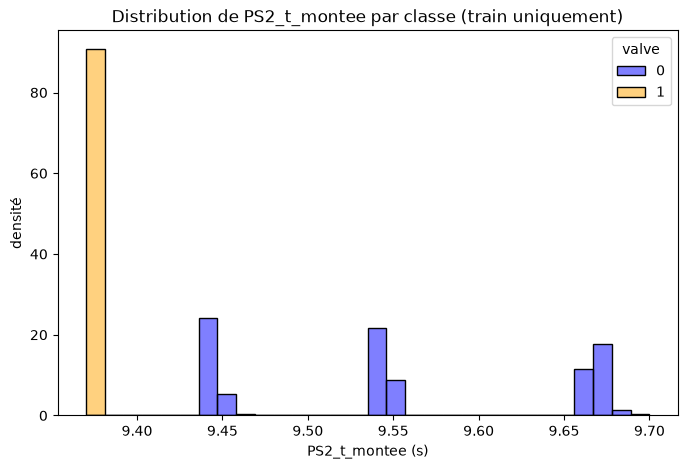

In [33]:
# Visualisation des points de la feature PS2_t_montee par rapport à la cible y_train
plt.figure(figsize=(8, 5))
sns.histplot(x=X_train["PS2_t_montee"], hue=y_train, bins=30, stat="density", common_norm=False, palette=["blue", "orange"])
plt.title("Distribution de PS2_t_montee par classe (train uniquement)")
plt.xlabel("PS2_t_montee (s)")
plt.ylabel("densité")
plt.show()

In [34]:
## Plot en sccatter 

### 4.2 `PS2_s09` seule face aux modèles complets

Une seule feature suffit-elle ? On compare, avec le même protocole :
1. régression logistique sur `PS2_s09` seule ;
2. régression logistique sur toutes les features ;
3. Random Forest sur toutes les features.

À performance égale, on garde le modèle le plus simple.

In [35]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

toutes = list(X_train.columns)
without_ps2_s09 = [c for c in toutes if c != "PS2_s09"]
without_t_montee = [c for c in toutes if c not in ["PS2_t_montee", "FS1_t_montee"]]
without_ps2_s09_t_montee = [c for c in toutes if c not in ["PS2_s09", "PS2_t_montee", "FS1_t_montee"]]

modeles = {
    "Logistique, PS2_s09 seule":     (["PS2_s09"], make_pipeline(StandardScaler(), LogisticRegression())),
    "KNN, PS2_s09 seule": (["PS2_s09"], make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))),
    "Logistique, toutes features":   (toutes, make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))),
    "Logistique, sans PS2_s09":      (without_ps2_s09, make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))),
    "Random Forest, toutes features": (toutes, RandomForestClassifier(n_estimators=300, random_state=0, n_jobs=-1)),
}

resultats = pd.concat({nom: evaluer(cols, modele) for nom, (cols, modele) in modeles.items()})
resultats

balanced_accuracy  roc_auc
Logistique, PS2_s09 seule      mean              1.000      1.0
                               std               0.000      0.0
KNN, PS2_s09 seule             mean              1.000      1.0
                               std               0.000      0.0
Logistique, toutes features    mean              1.000      1.0
                               std               0.000      0.0
Logistique, sans PS2_s09       mean              0.998      1.0
                               std               0.002      0.0
Random Forest, toutes features mean              1.000      1.0
                               std               0.000      0.0

**Lecture :** les trois modèles ont un score parfait (1,0 avec un écart-type nul), comme `PS2_t_montee` seule en 4.1. Ajouter des features ou un modèle plus flexible n'apporte rien.

**Choix :** une régression logistique sur **une seule feature**. On évalue les deux candidats sur le test.

#### Courbes d'apprentissage : y a-t-il de l'overfitting ?

**Principe.** On entraîne chaque modèle sur une part croissante du train (10 % à 100 %
des cycles d'entraînement de chaque fold) et on trace deux scores :
- **score d'entraînement** : mesuré sur les cycles qui ont servi à apprendre ;
- **score de validation** : mesuré sur les blocs mis de côté (même `GroupKFold` que `evaluer()`).

**Deux métriques :** la balanced accuracy vaut 1 presque partout et ne montrerait aucun
écart. On trace donc aussi la **log-loss** : elle mesure la confiance des probabilités et
révèle un écart train/validation même quand toutes les prédictions sont justes.

In [36]:
from sklearn.model_selection import learning_curve
def courbe_apprentissage(colonnes, modele, scoring):
    """Scores d'entraînement et de validation pour des tailles de train croissantes.
    Même découpage par blocs que evaluer() : le test n'est jamais utilisé."""
    tailles, sc_tr, sc_val = learning_curve(
        modele, X_train[colonnes], y_train, groups=groups, cv=cv,
        train_sizes=TAILLES, scoring=scoring,
        shuffle=True, random_state=0,   # sinon les petits sous-échantillons (cycles consécutifs) n'ont qu'une classe
        n_jobs=-1)
    if scoring.startswith("neg_"):      # sklearn renvoie -log-loss : on remet le signe
        sc_tr, sc_val = -sc_tr, -sc_val
    return tailles, sc_tr, sc_val

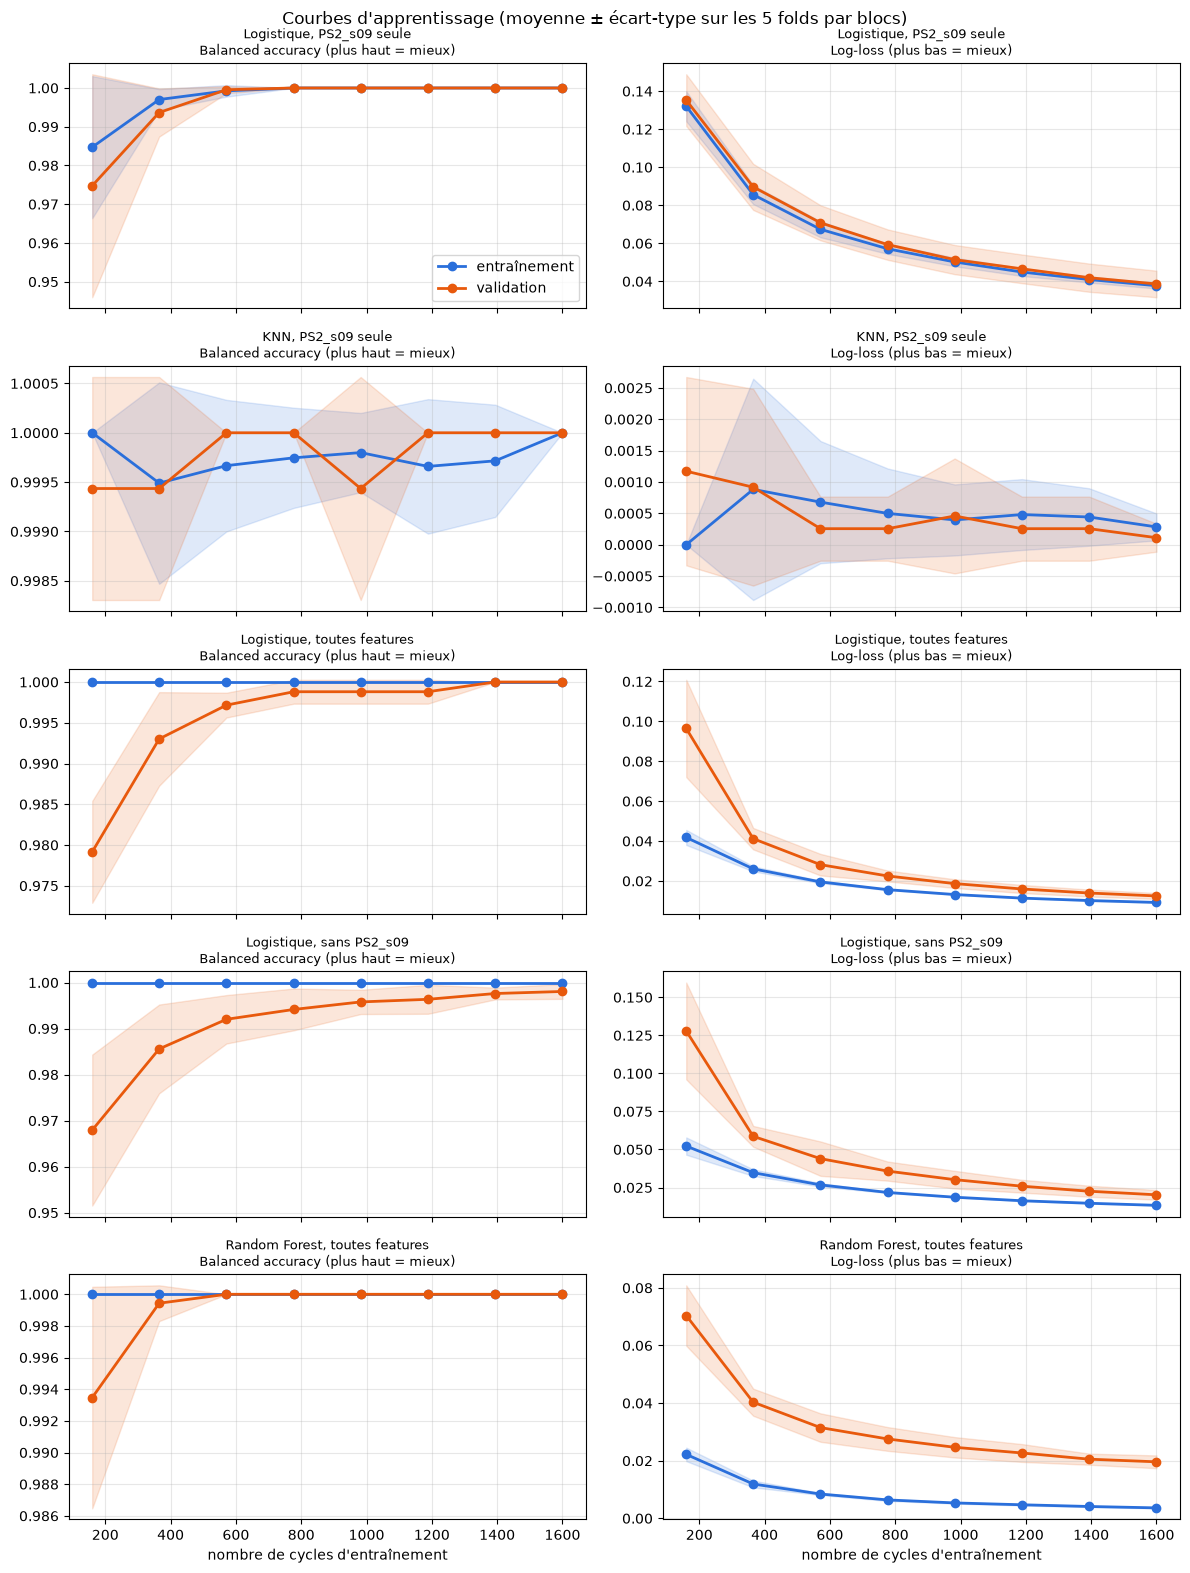

In [37]:
TAILLES = np.linspace(0.1, 1.0, 8)   # part des cycles d'entraînement de chaque fold
METRIQUES = {"balanced_accuracy": "Balanced accuracy (plus haut = mieux)",
             "neg_log_loss":      "Log-loss (plus bas = mieux)"}
COULEURS = {"entraînement": "#2a6fdb", "validation": "#e8590c"}

fig, axes = plt.subplots(len(modeles), 2, figsize=(12, 3.2 * len(modeles)), sharex=True)
for ligne, (nom, (cols, modele)) in zip(axes, modeles.items()):
    for ax, (scoring, titre) in zip(ligne, METRIQUES.items()):
        tailles, sc_tr, sc_val = courbe_apprentissage(cols, modele, scoring)
        for label, sc in [("entraînement", sc_tr), ("validation", sc_val)]:
            moy, et = sc.mean(axis=1), sc.std(axis=1)
            ax.plot(tailles, moy, marker="o", lw=2, color=COULEURS[label], label=label)
            ax.fill_between(tailles, moy - et, moy + et, color=COULEURS[label], alpha=0.15)
        ax.set_title(f"{nom}\n{titre}", fontsize=9)
        ax.grid(alpha=0.3)
axes[0, 0].legend()
for ax in axes[-1]:
    ax.set_xlabel("nombre de cycles d'entraînement")
fig.suptitle("Courbes d'apprentissage (moyenne ± écart-type sur les 5 folds par blocs)")
plt.tight_layout()
plt.show()

## 5. Évaluation finale sur le test

Chaque modèle est entraîné sur les 2000 cycles du train, puis évalué une seule fois sur les 205 cycles du test.

### 5.1 `PS2_s09` seule

Balanced accuracy (test) : 1.000
ROC AUC (test)           : 1.000

                 precision    recall  f1-score   support

0 = non optimal       1.00      1.00      1.00       132
    1 = optimal       1.00      1.00      1.00        73

       accuracy                           1.00       205
      macro avg       1.00      1.00      1.00       205
   weighted avg       1.00      1.00      1.00       205



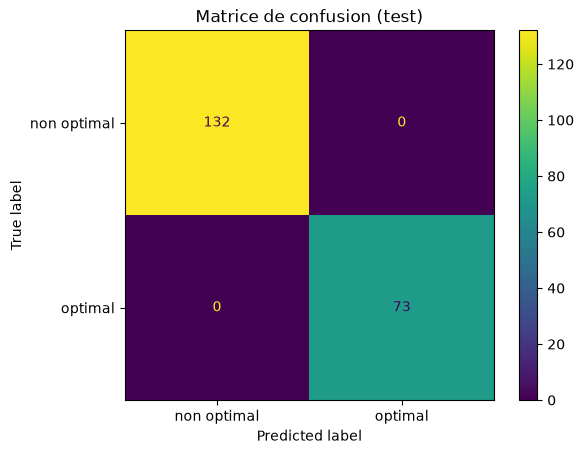

In [38]:
from sklearn.metrics import (balanced_accuracy_score, roc_auc_score,
                             classification_report, ConfusionMatrixDisplay)

# Entraînement sur tout le train (plus de folds : le choix est fait)
modele_final = make_pipeline(StandardScaler(), LogisticRegression())
modele_final.fit(X_train[["PS2_s09"]], y_train)

# Prédictions sur le test
y_pred  = modele_final.predict(X_test[["PS2_s09"]])
y_proba = modele_final.predict_proba(X_test[["PS2_s09"]])[:, 1]

print(f"Balanced accuracy (test) : {balanced_accuracy_score(y_test, y_pred):.3f}")
print(f"ROC AUC (test)           : {roc_auc_score(y_test, y_proba):.3f}\n")
print(classification_report(y_test, y_pred, target_names=["0 = non optimal", "1 = optimal"]))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["non optimal", "optimal"])
plt.title("Matrice de confusion (test)")
plt.show()

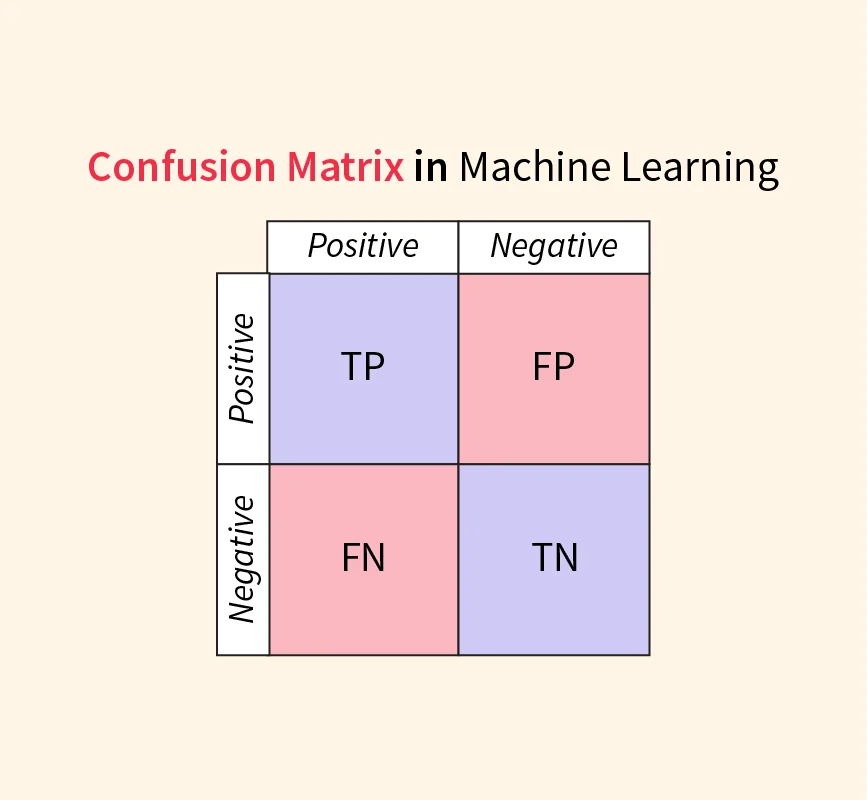

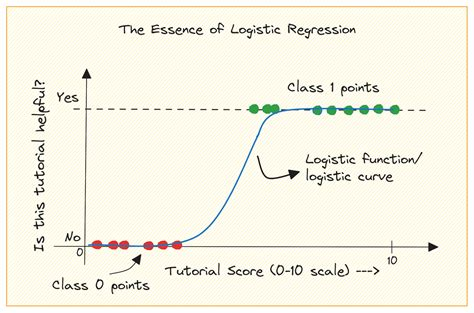

In [39]:
# Prédictions par niveau réel de valve
pd.crosstab(df_profile["valve"].iloc[N_TRAIN:].values, y_pred,
            rownames=["valve réelle (%)"], colnames=["prédiction"])

prédiction,0,1
valve réelle (%),,
73,40,0
80,42,0
90,50,0
100,0,73


In [40]:
scaler = modele_final.named_steps["standardscaler"]
logreg = modele_final.named_steps["logisticregression"]

# Frontière de décision : w * z + b = 0, avec z = (x - moyenne) / écart-type
seuil = scaler.mean_[0] - logreg.intercept_[0] * scaler.scale_[0] / logreg.coef_[0, 0]
print(f"Seuil appris : le cycle est prédit optimal si PS2_s09 > {seuil:.2f} bar")

Seuil appris : le cycle est prédit optimal si PS2_s09 > 77.96 bar


**Résultats :** balanced accuracy = AUC = 1,000, aucune erreur : les trois niveaux dégradés (73, 80 et 90 %) sont tous détectés.

**Interprétation :** le modèle revient à un seuil, **optimal si `PS2_s09` > 77,96 bar**. Une valve dégradée commute plus tard, donc la pression moyenne de cette seconde baisse.

**Limite :** sur le train, l'écart entre les classes ne fait que 0,9 bar (77,4 contre 78,3 bar) : c'est là qu'une erreur apparaîtrait en premier si les conditions changeaient.

### 5.2 `PS2_t_montee` seule

Balanced accuracy (test) : 1.000
ROC AUC (test)           : 1.000

                 precision    recall  f1-score   support

0 = non optimal       1.00      1.00      1.00       132
    1 = optimal       1.00      1.00      1.00        73

       accuracy                           1.00       205
      macro avg       1.00      1.00      1.00       205
   weighted avg       1.00      1.00      1.00       205



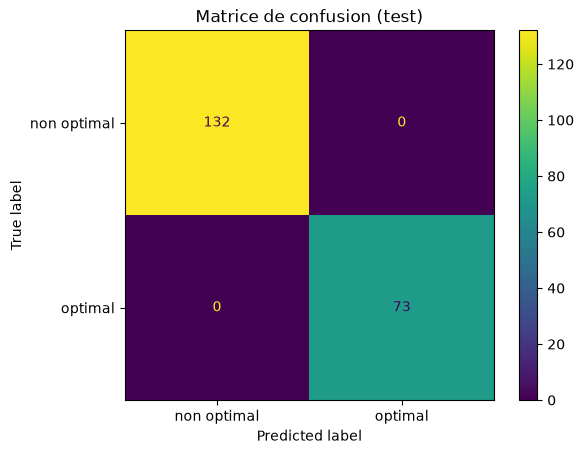

In [41]:
#### On va effectuer la logistic regression sur la feature X["PS2_t_montee"] (le temps de montée de la pression PS2) pour voir si elle est plus discriminante que PS2_s09.
from sklearn.metrics import (balanced_accuracy_score, roc_auc_score,
                             classification_report, ConfusionMatrixDisplay)

# Entraînement sur tout le train (plus de folds : le choix est fait)
modele_final = make_pipeline(StandardScaler(), LogisticRegression())
modele_final.fit(X_train[["PS2_t_montee"]], y_train)

# Prédictions sur le test
y_pred  = modele_final.predict(X_test[["PS2_t_montee"]])
y_proba = modele_final.predict_proba(X_test[["PS2_t_montee"]])[:, 1]

print(f"Balanced accuracy (test) : {balanced_accuracy_score(y_test, y_pred):.3f}")
print(f"ROC AUC (test)           : {roc_auc_score(y_test, y_proba):.3f}\n")
print(classification_report(y_test, y_pred, target_names=["0 = non optimal", "1 = optimal"]))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["non optimal", "optimal"])
plt.title("Matrice de confusion (test)")
plt.show()

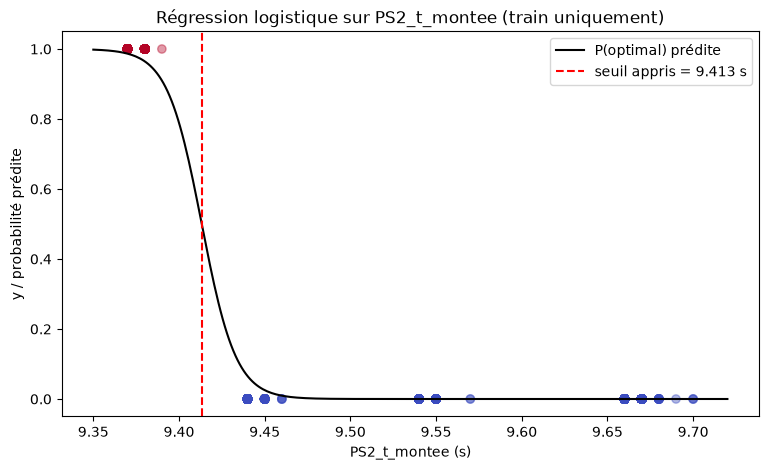

In [42]:
# Modèle entraîné sur tout le train pour pouvoir le tracer
modele_tm = make_pipeline(StandardScaler(), LogisticRegression())
modele_tm.fit(X_train[["PS2_t_montee"]], y_train)

# Seuil appris : même calcul qu'en 5.1
sc = modele_tm.named_steps["standardscaler"]
lr = modele_tm.named_steps["logisticregression"]
seuil_tm = sc.mean_[0] - lr.intercept_[0] * sc.scale_[0] / lr.coef_[0, 0]

# Courbe logistique
x_grid = pd.DataFrame({"PS2_t_montee": np.linspace(9.35, 9.72, 300)})
proba = modele_tm.predict_proba(x_grid)[:, 1]

plt.figure(figsize=(9, 5))
plt.scatter(X_train["PS2_t_montee"], y_train, c=y_train, cmap="coolwarm", alpha=0.4)
plt.plot(x_grid["PS2_t_montee"], proba, color="black", label="P(optimal) prédite")
plt.axvline(seuil_tm, color="red", linestyle="--", label=f"seuil appris = {seuil_tm:.3f} s")
plt.xlabel("PS2_t_montee (s)")
plt.ylabel("y / probabilité prédite")
plt.title("Régression logistique sur PS2_t_montee (train uniquement)")
plt.legend()
plt.show()


## 6. Conclusion

- L'état de la valve se lit dans **un seul phénomène** : le retard de la montée en pression vers 9 s.
- Deux modèles à une seule feature obtiennent un score parfait, en validation croisée comme sur le test (balanced accuracy = AUC = 1,000).
- `PS2_s09` donne une règle très simple (seuil à 77,96 bar), mais avec une faible marge et une sensibilité au cooler.
- `PS2_t_montee` mesure directement le phénomène, avec une marge 7 fois plus grande : c'est la feature la plus robuste pour un usage en production.